# 1. Random Walks

*Part 1 of **Stochastic Modelling and Monte Carlo Methods for Financial Markets**.*

The random walk is the simplest stochastic process and the discrete ancestor of Brownian motion, which drives every model in the rest of this project.

This notebook covers:

1. the simple symmetric random walk;
2. how variance grows linearly with time;
3. adding a drift;
4. the scaling limit that connects random walks to Brownian motion.

At each time step the process moves up by one unit with probability $p$ and down by one unit with probability $1-p$. The position at time $t$ is

$$
S_t = S_0 + \sum_{i=1}^{t} X_i, \qquad X_i \in \{-1, +1\}.
$$

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Make the project's src/ package importable when running from notebooks/
sys.path.insert(0, str(Path.cwd().parent / "src"))

from stochmc import scaled_random_walk, simulate_random_walks

SEED = 42
rng = np.random.default_rng(SEED)

## 1.1 A single symmetric random walk

With $p = 0.5$ the walk has no tendency to move up or down.

In [2]:
n_steps = 100
initial_position = 0
probability_up = 0.5

steps = rng.choice(
    [-1, 1],
    size=n_steps,
    p=[1 - probability_up, probability_up]
)

positions = np.concatenate(
    ([initial_position], initial_position + np.cumsum(steps))
)

time = np.arange(n_steps + 1)

walk_data = pd.DataFrame({
    "time": time,
    "position": positions
})

walk_data.head(10)

,time,position
0,0,0
1,1,1
2,2,0
3,3,1
4,4,2
5,5,1
6,6,2
7,7,3
8,8,4
9,9,3


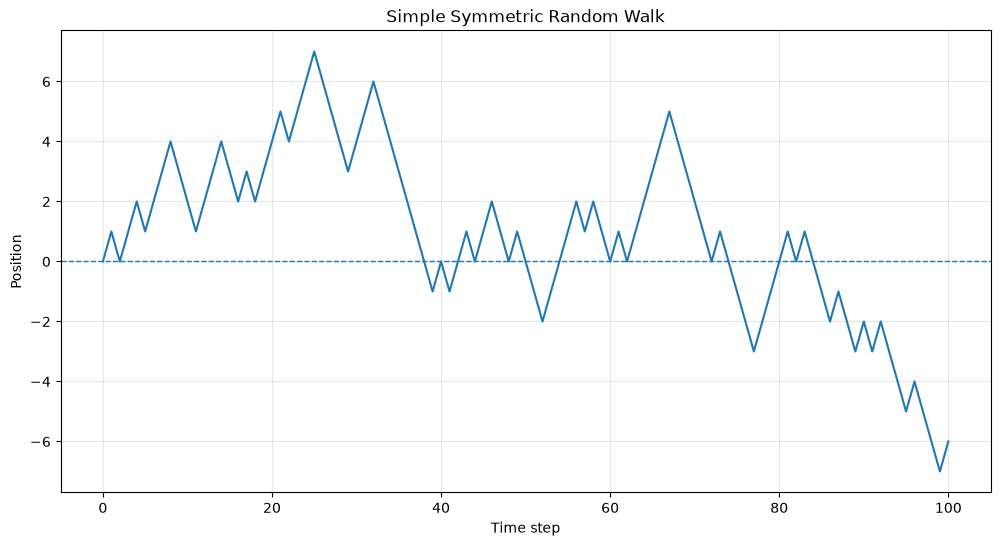

In [3]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    walk_data["time"],
    walk_data["position"],
    linewidth=1.5
)

ax.axhline(
    y=initial_position,
    linestyle="--",
    linewidth=1
)

ax.set_title("Simple Symmetric Random Walk")
ax.set_xlabel("Time step")
ax.set_ylabel("Position")
ax.grid(alpha=0.3)

plt.show()

In [4]:
walk_summary = pd.Series({
    "number_of_steps": n_steps,
    "final_position": positions[-1],
    "minimum_position": positions.min(),
    "maximum_position": positions.max(),
    "number_of_up_steps": np.sum(steps == 1),
    "number_of_down_steps": np.sum(steps == -1),
    "average_step": steps.mean()
})

walk_summary

number_of_steps         100.00
final_position           -6.00
minimum_position         -7.00
maximum_position          7.00
number_of_up_steps       47.00
number_of_down_steps     53.00
average_step             -0.06
dtype: float64

In [5]:
assert len(steps) == n_steps
assert len(positions) == n_steps + 1
assert positions[0] == initial_position
assert np.all(np.isin(steps, [-1, 1]))
assert positions[-1] == initial_position + steps.sum()

print("All consistency checks passed.")

All consistency checks passed.


## 1.2 Variance growing with time

A single path need not stay near zero. For the symmetric walk each step has $\mathbb{E}[X_i] = 0$ and $\operatorname{Var}(X_i) = 1$, and the steps are independent, so

$$
\mathbb{E}[S_t] = S_0, \qquad \operatorname{Var}(S_t) = t, \qquad \operatorname{Std}(S_t) = \sqrt{t}.
$$

The expected position stays the same while uncertainty grows like $\sqrt{t}$. We check this by simulating many independent walks.

In [6]:
n_simulations = 10_000

all_positions = simulate_random_walks(
    n_paths=n_simulations,
    n_steps=n_steps,
    rng=rng,
    probability_up=probability_up,
    initial_position=initial_position
)

all_positions.shape

(10000, 101)

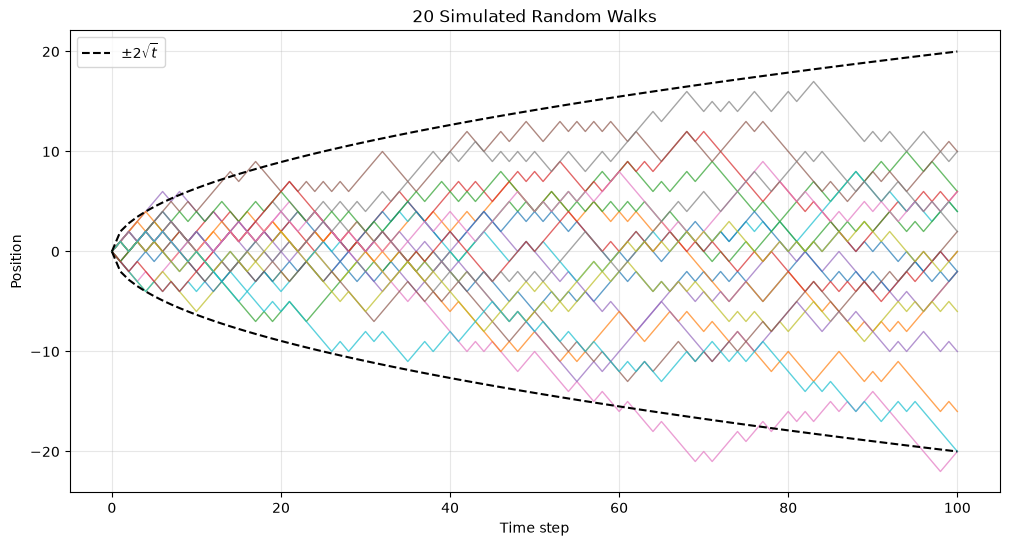

In [7]:
n_paths_to_plot = 20

fig, ax = plt.subplots(figsize=(12, 6))

for i in range(n_paths_to_plot):
    ax.plot(time, all_positions[i], linewidth=1, alpha=0.7)

# The +/- 2 standard deviation envelope contains roughly 95% of positions
ax.plot(time, 2 * np.sqrt(time), color="black", linestyle="--", label=r"$\pm 2\sqrt{t}$")
ax.plot(time, -2 * np.sqrt(time), color="black", linestyle="--")

ax.set_title(f"{n_paths_to_plot} Simulated Random Walks")
ax.set_xlabel("Time step")
ax.set_ylabel("Position")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

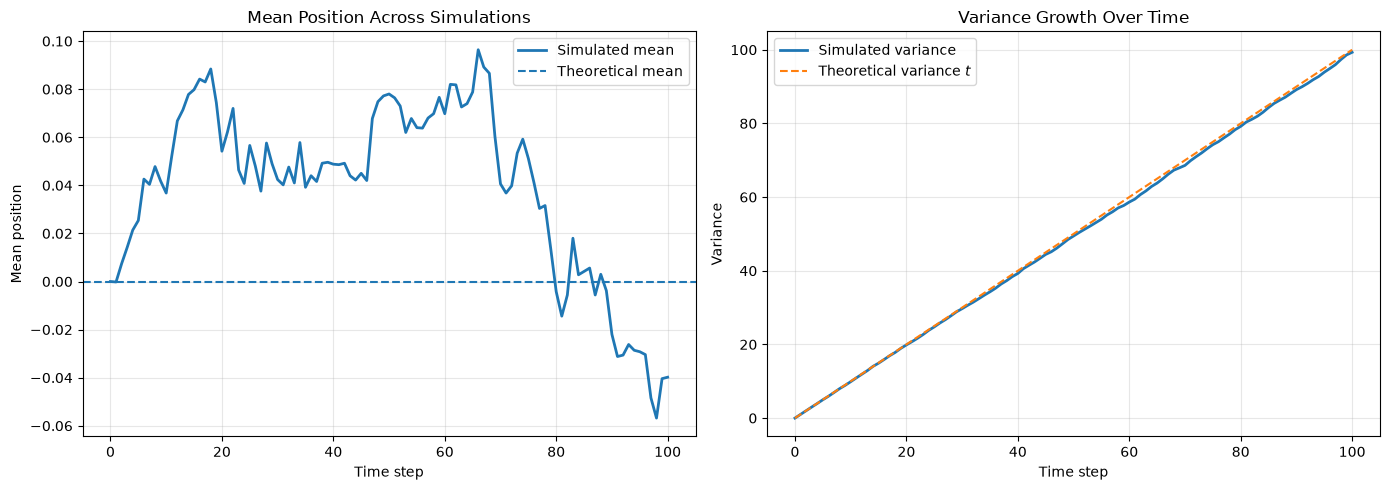

In [8]:
simulated_mean = all_positions.mean(axis=0)
simulated_variance = all_positions.var(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(time, simulated_mean, linewidth=2, label="Simulated mean")
axes[0].axhline(y=initial_position, linestyle="--", label="Theoretical mean")
axes[0].set_title("Mean Position Across Simulations")
axes[0].set_xlabel("Time step")
axes[0].set_ylabel("Mean position")

axes[1].plot(time, simulated_variance, linewidth=2, label="Simulated variance")
axes[1].plot(time, time, linestyle="--", label="Theoretical variance $t$")
axes[1].set_title("Variance Growth Over Time")
axes[1].set_xlabel("Time step")
axes[1].set_ylabel("Variance")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

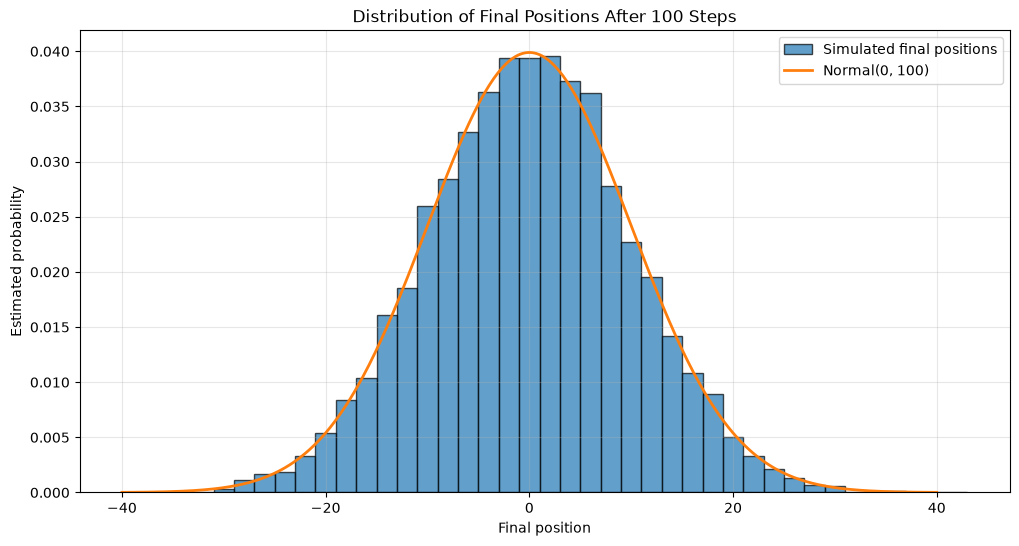

In [9]:
final_positions = all_positions[:, -1]

fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    final_positions,
    bins=np.arange(
        final_positions.min() - 1,
        final_positions.max() + 2,
        2
    ),
    density=True,
    edgecolor="black",
    alpha=0.7,
    label="Simulated final positions"
)

# Positions after an even number of steps are always even, so each
# histogram bar of width 2 is compared with a normal density
position_grid = np.linspace(-40, 40, 400)
ax.plot(
    position_grid,
    stats.norm.pdf(position_grid, loc=initial_position, scale=np.sqrt(n_steps)),
    linewidth=2,
    label=f"Normal(0, {n_steps})"
)

ax.set_title(f"Distribution of Final Positions After {n_steps} Steps")
ax.set_xlabel("Final position")
ax.set_ylabel("Estimated probability")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

In [10]:
pd.Series({
    "simulated_final_mean": final_positions.mean(),
    "theoretical_final_mean": initial_position,
    "simulated_final_variance": final_positions.var(),
    "theoretical_final_variance": n_steps,
    "simulated_final_std": final_positions.std(),
    "theoretical_final_std": np.sqrt(n_steps),
    "P(final position > 0)": np.mean(final_positions > 0),
    "P(final position < 0)": np.mean(final_positions < 0),
    "P(final position = 0)": np.mean(final_positions == 0)
})

simulated_final_mean           -0.039800
theoretical_final_mean          0.000000
simulated_final_variance       99.306016
theoretical_final_variance    100.000000
simulated_final_std             9.965240
theoretical_final_std          10.000000
P(final position > 0)           0.461100
P(final position < 0)           0.460200
P(final position = 0)           0.078700
dtype: float64

The histogram already looks Gaussian. This is the central limit theorem at work: $S_t$ is a sum of $t$ independent steps, so $S_t \approx \mathcal{N}(S_0, t)$ for large $t$.

In [11]:
assert all_positions.shape == (n_simulations, n_steps + 1)
assert np.all(all_positions[:, 0] == initial_position)
assert np.all(np.isin(np.diff(all_positions, axis=1), [-1, 1]))
assert abs(final_positions.var() / n_steps - 1) < 0.05

print("Monte Carlo simulation checks passed.")

Monte Carlo simulation checks passed.


## 1.3 Adding drift

If $p \neq 0.5$ the walk has a systematic tendency. A single step then has

$$
\mathbb{E}[X_i] = 2p - 1, \qquad \operatorname{Var}(X_i) = 4p(1-p),
$$

so after $t$ steps

$$
\mathbb{E}[S_t] = S_0 + (2p-1)\,t, \qquad \operatorname{Var}(S_t) = 4p(1-p)\,t.
$$

The **drift** grows linearly in $t$ while the **noise** grows only like $\sqrt{t}$. Over short horizons randomness dominates; over long horizons the drift wins. The same tension between $\mu\,dt$ and $\sigma\,dW_t$ reappears in Geometric Brownian Motion.

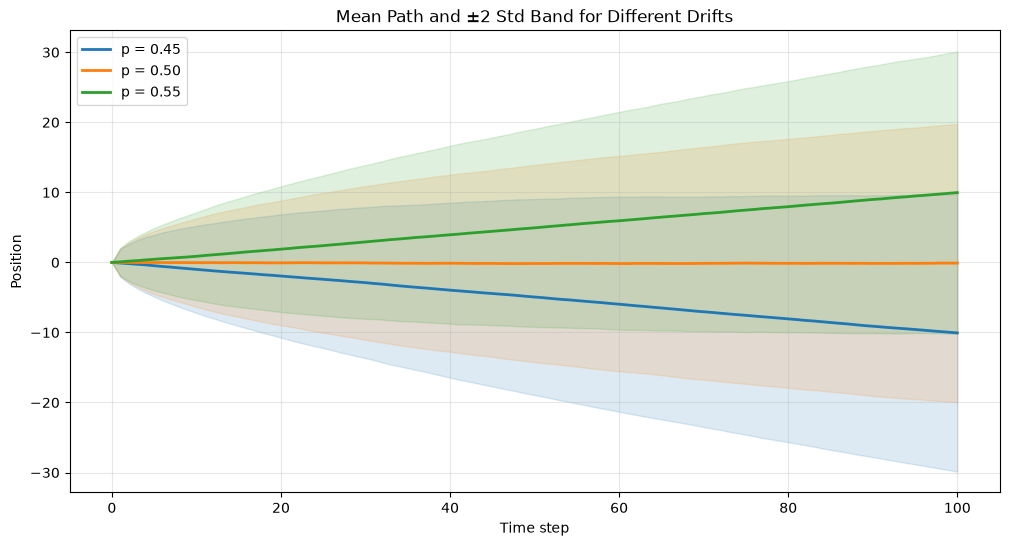

,simulated_final_mean,theoretical_final_mean,simulated_final_variance,theoretical_final_variance
p,,,,
0.45,-10.0706,-10.0,97.815416,99.0
0.50,-0.1006,0.0,98.606280,100.0
0.55,9.9598,10.0,101.479584,99.0


In [12]:
probabilities_up = [0.45, 0.50, 0.55]

fig, ax = plt.subplots(figsize=(12, 6))

drift_summary = []

for p in probabilities_up:
    drift_positions = simulate_random_walks(
        n_paths=n_simulations,
        n_steps=n_steps,
        rng=rng,
        probability_up=p,
        initial_position=initial_position
    )

    mean_path = drift_positions.mean(axis=0)
    std_path = drift_positions.std(axis=0)

    line, = ax.plot(time, mean_path, linewidth=2, label=f"p = {p:.2f}")
    ax.fill_between(
        time,
        mean_path - 2 * std_path,
        mean_path + 2 * std_path,
        color=line.get_color(),
        alpha=0.15
    )

    drift_summary.append({
        "p": p,
        "simulated_final_mean": drift_positions[:, -1].mean(),
        "theoretical_final_mean": initial_position + (2 * p - 1) * n_steps,
        "simulated_final_variance": drift_positions[:, -1].var(),
        "theoretical_final_variance": 4 * p * (1 - p) * n_steps
    })

ax.set_title("Mean Path and ±2 Std Band for Different Drifts")
ax.set_xlabel("Time step")
ax.set_ylabel("Position")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

pd.DataFrame(drift_summary).set_index("p")

With $p = 0.55$ the expected position after 100 steps is $+10$ but the standard deviation is still about $9.95$, so a large fraction of paths still end below zero. The drift only dominates the noise once $(2p-1)\,t \gg 2\sqrt{p(1-p)}\,\sqrt{t}$, i.e. for long horizons.

## 1.4 From random walks to Brownian motion

Shrink time and space together: take $n$ steps per unit of time and scale each step by $1/\sqrt{n}$,

$$
W^{(n)}_t = \frac{1}{\sqrt{n}} \, S_{\lfloor nt \rfloor}.
$$

For every $n$ this keeps $\operatorname{Var}(W^{(n)}_t) \approx t$. As $n \to \infty$, **Donsker's theorem** says $W^{(n)}$ converges in distribution to a standard **Brownian motion** $W_t$, which has

- $W_0 = 0$;
- independent increments;
- $W_t - W_s \sim \mathcal{N}(0,\, t-s)$;
- continuous (but nowhere differentiable) paths.

The $\sqrt{n}$ scaling is the only one with a non-trivial limit: scaling by $1/n$ collapses the walk to zero, and no scaling makes it explode.

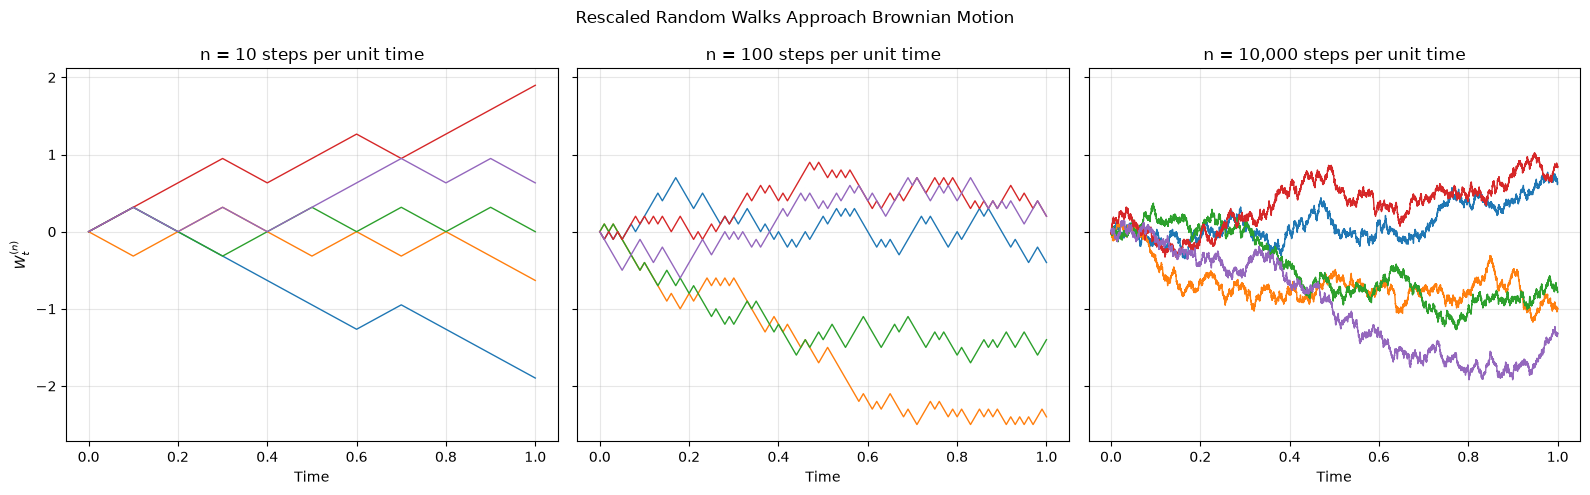

In [13]:
steps_per_unit_time_values = [10, 100, 10_000]
time_horizon = 1.0

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, n in zip(axes, steps_per_unit_time_values):
    scaled_time, scaled_paths = scaled_random_walk(
        n_paths=5,
        steps_per_unit_time=n,
        time_horizon=time_horizon,
        rng=rng
    )

    for path in scaled_paths:
        ax.plot(scaled_time, path, linewidth=1)

    ax.set_title(f"n = {n:,} steps per unit time")
    ax.set_xlabel("Time")
    ax.grid(alpha=0.3)

axes[0].set_ylabel(r"$W^{(n)}_t$")
fig.suptitle("Rescaled Random Walks Approach Brownian Motion")
plt.tight_layout()
plt.show()

As $n$ grows the paths lose their staircase shape and look like Brownian motion. The distribution of $W^{(n)}_1$ also converges to $\mathcal{N}(0, 1)$:

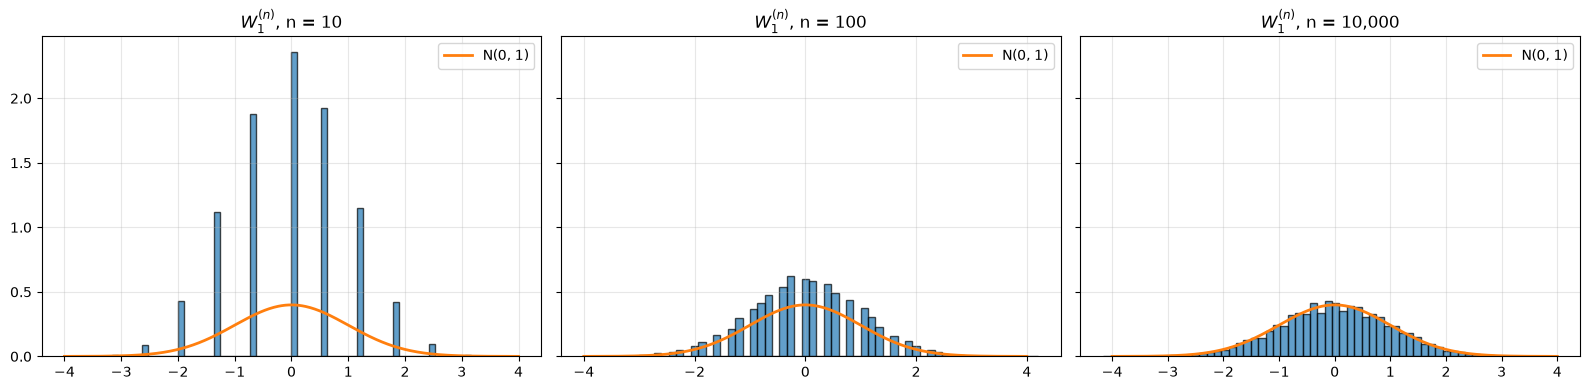

,mean,variance,ks_distance_to_normal
n,,,
10,0.007115,1.008729,0.128550
100,0.003530,1.000482,0.046040
10000,0.005687,1.004712,0.007345


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
grid = np.linspace(-4, 4, 400)

convergence_rows = []

for ax, n in zip(axes, steps_per_unit_time_values):
    _, scaled_paths = scaled_random_walk(
        n_paths=20_000,
        steps_per_unit_time=n,
        time_horizon=time_horizon,
        rng=rng
    )
    terminal_values = scaled_paths[:, -1]

    ax.hist(terminal_values, bins=60, density=True, alpha=0.7, edgecolor="black")
    ax.plot(grid, stats.norm.pdf(grid), linewidth=2, label="N(0, 1)")
    ax.set_title(f"$W^{{(n)}}_1$, n = {n:,}")
    ax.legend()
    ax.grid(alpha=0.3)

    convergence_rows.append({
        "n": n,
        "mean": terminal_values.mean(),
        "variance": terminal_values.var(),
        # Kolmogorov-Smirnov distance to the standard normal distribution
        "ks_distance_to_normal": stats.kstest(terminal_values, "norm").statistic
    })

plt.tight_layout()
plt.show()

pd.DataFrame(convergence_rows).set_index("n")

### Quadratic variation: why $dW_t^2 = dt$

Brownian increments over a step $\Delta t$ have size about $\sqrt{\Delta t}$, so their squares are about $\Delta t$. Summing squared increments over $[0, T]$ gives

$$
\sum_{i} \left(W_{t_{i+1}} - W_{t_i}\right)^2 \;\longrightarrow\; T \quad \text{as } \Delta t \to 0,
$$

and this limit is not random. In the rescaled walk every squared increment is exactly $1/n$, so the sum is exactly $T$. This property, usually written $(dW_t)^2 = dt$, is the extra term in **Itô's lemma**. It produces the $-\tfrac{1}{2}\sigma^2$ correction in Geometric Brownian Motion in the next notebook.

In [15]:
_, fine_paths = scaled_random_walk(
    n_paths=1_000,
    steps_per_unit_time=10_000,
    time_horizon=time_horizon,
    rng=rng
)

increments = np.diff(fine_paths, axis=1)

pd.Series({
    "sum_of_squared_increments (mean)": (increments**2).sum(axis=1).mean(),
    "sum_of_squared_increments (std)": (increments**2).sum(axis=1).std(),
    "sum_of_absolute_increments (mean)": np.abs(increments).sum(axis=1).mean(),
    "time_horizon": time_horizon
})

sum_of_squared_increments (mean)     1.000000e+00
sum_of_squared_increments (std)      1.455197e-16
sum_of_absolute_increments (mean)    1.000000e+02
time_horizon                         1.000000e+00
dtype: float64

The sum of squared increments equals $T = 1$ on every path, with zero spread. The sum of *absolute* increments (the total variation) is $\sqrt{n} = 100$ and grows without bound as $n$ increases. Brownian paths are therefore far too rough for ordinary calculus, which is why stochastic calculus is needed.

## Conclusions

- A symmetric random walk keeps its expected value but its variance grows linearly with time: $\operatorname{Var}(S_t) = t$.
- Adding drift shifts the mean linearly in $t$, while the noise grows only like $\sqrt{t}$.
- By the central limit theorem, positions are approximately normal.
- Rescaling time by $n$ and space by $\sqrt{n}$ turns the walk into Brownian motion, which has Gaussian independent increments and quadratic variation $T$.

Brownian motion can be negative and has additive increments, so it is a poor direct model for prices. The next notebook uses it as the source of randomness in **Geometric Brownian Motion**.